# Programación semanal iterativa de rutas y descargas

## 1. Modelo matemático y lógica de solución

**Objetivo.** Asignar las rutas flexibles a días de la semana, secuenciar las rutas de cada vehículo y programar su descarga en **tres bahías compartidas**. Cada ruta se ejecuta exactamente una vez y siempre con su vehículo original. Las rutas fijas conservan su día. Las duraciones ya incluyen el retorno al centro de descarga.

**Variables por ruta $i$:** 
- $x_i$ inicio de ruta; 
- $a_i=x_i+t_i$ llegada al centro; 
- $s_i$ inicio de descarga; 
- $f_i=s_i+p$ fin de descarga; 
- $w_i=s_i-a_i\geq0$ espera en cola. 
- $z_{im}$ indica bahía asignada y las binarias de precedencia ordenan rutas y descargas. 

**Por vehículo y día:** 
- $e_{vd}\geq0$ mide minutos posteriores al fin de jornada. 
- el inicio de la primera ruta de cada vehículo que opera ese día se fija a las 07:00 (mediante restricción de mínimo inicio).
- entre rutas hay un intervalo mínimo $\tau$ que sería un tiempo ocioso.

**Objetivo diario ponderado:**
$$\min\ Z_d=\alpha\sum_{i\in J_d}w_i+\beta\sum_{v\in V}e_{vd}$$
El algoritmo semanal busca minimizar $Z(S)=\sum_d Z_d(S)$, con $S$ la asignación de rutas a días. 
Se reportan **por separado** espera total, horas extra y ocio adicional entre rutas; este último no se penaliza en esta versión. 
La jornada deja de ser una restricción dura: $f_i\le H^{fin}+e_{vd}$, opcionalmente $e_{vd}\le E^{max}$.

**Restricciones esenciales:** 
- cada descarga usa exactamente una bahía; 
- no hay solapamiento en la misma bahía; 
- las rutas del mismo vehículo no se solapan y entre descarga y siguiente salida transcurren al menos $\tau$; 
- cada ruta fija conserva su día; 
- una flexible puede cambiar de día **solo dentro de los días permitidos**; 
- las descargas se planifican anticipadamente; **no se impone FIFO estricto**.

### Algoritmo híbrido VNS + MILP diario

1. Construir una configuración inicial semanal (datos **aleatorios** o **manuales**).
2. Resolver el MILP de cada día y registrar tiempos de cola, extraordinarios y ocio.
3. Generar un vecino mediante **mover**, **intercambiar** o **reorganizar** rutas flexibles del mismo vehículo.
4. Reoptimizar **únicamente los días modificados**, reutilizando resultados de los demás días.
5. Conservar la mejor solución y detenerse al llegar al máximo de iteraciones o al límite de iteraciones sin mejora.

Si el MILP diario alcanza el límite de tiempo, se acepta solo una solución factible disponible y se identifica su estado. 
Una asignación que supere la jornada **no se descarta**, se mide el tiempo extraordinario.


## 2. Configuración inicial editable

Seleccionar `MODO_DATOS = "manual"` o `"aleatorio"`.

**Modo manual:** para editar por separado `RUTAS_FIJAS` y `RUTAS_FLEXIBLES`. Cada duración representa una ruta; **no existe una proporción obligatoria entre fijas y flexibles**. Las rutas fijas se indican por vehículo y día. Cada flexible tiene su propio identificador, duración, día inicial y días permitidos.

**Modo aleatorio:** para modificar `FIJAS_POR_DIA`, `FLEXIBLES_POR_VEHICULO` y los rangos de duración. Los números de rutas también pueden ser distintos por vehículo o día.

**Importante:** las duraciones incluyen el regreso al centro de descarga; no incluyen los 20 minutos de descarga. El modelo admite tiempo extraordinario y lo penaliza. La factibilidad final depende de la optimización diaria de todos los vehículos y bahías, no solo de la suma de duraciones.

In [43]:
# --- Definición de datos para MODO_DATOS = "manual" ---
RUTAS_FIJAS = [
    ("V01", "V01-F01-D01", "Lunes", 188),
    ("V01", "V01-F01-D02", "Martes", 205),
    ("V01", "V01-F01-D03", "Miércoles", 174),
    ("V01", "V01-F01-D04", "Jueves", 201),
    ("V01", "V01-F01-D05", "Viernes", 190),
    ("V02", "V02-F01-D01", "Lunes", 199),
    ("V02", "V02-F01-D02", "Martes", 184),
    ("V02", "V02-F01-D03", "Miércoles", 211),
    ("V02", "V02-F01-D04", "Jueves", 187),
    ("V02", "V02-F01-D05", "Viernes", 195),
    ("V03", "V03-F01-D01", "Lunes", 177),
    ("V03", "V03-F01-D02", "Martes", 200),
    ("V03", "V03-F01-D03", "Miércoles", 192),
    ("V03", "V03-F01-D04", "Jueves", 216),
    ("V03", "V03-F01-D05", "Viernes", 185),
    ("V04", "V04-F01-D01", "Lunes", 210),
    ("V04", "V04-F01-D02", "Martes", 193),
    ("V04", "V04-F01-D03", "Miércoles", 179),
    ("V04", "V04-F01-D04", "Jueves", 206),
    ("V04", "V04-F01-D05", "Viernes", 197),
]

RUTAS_FLEXIBLES = [
    ("V01", "V01-L01", "Lunes", 196, ["Lunes", "Martes", "Miércoles"]),
    ("V01", "V01-L02", "Martes", 178, ["Lunes", "Martes", "Miércoles", "Jueves"]),
    ("V01", "V01-L03", "Miércoles", 218, ["Martes", "Miércoles", "Jueves", "Viernes"]),
    ("V01", "V01-L04", "Jueves", 183, ["Miércoles", "Jueves", "Viernes"]),
    ("V01", "V01-L05", "Viernes", 202, ["Lunes", "Jueves", "Viernes"]),
    ("V02", "V02-L01", "Lunes", 190, ["Lunes", "Martes", "Miércoles", "Jueves"]),
    ("V02", "V02-L02", "Martes", 185, ["Martes", "Miércoles", "Jueves"]),
    ("V02", "V02-L03", "Miércoles", 207, ["Lunes", "Miércoles", "Viernes"]),
    ("V02", "V02-L04", "Jueves", 195, ["Martes", "Jueves", "Viernes"]),
    ("V02", "V02-L05", "Viernes", 188, ["Jueves", "Viernes"]),
    ("V03", "V03-L01", "Lunes", 198, ["Lunes", "Martes", "Miércoles"]),
    ("V03", "V03-L02", "Martes", 203, ["Lunes", "Martes", "Miércoles", "Jueves"]),
    ("V03", "V03-L03", "Miércoles", 189, ["Miércoles", "Jueves", "Viernes"]),
    ("V03", "V03-L04", "Jueves", 212, ["Martes", "Jueves", "Viernes"]),
    ("V03", "V03-L05", "Viernes", 194, ["Jueves", "Viernes"]),
    ("V04", "V04-L01", "Lunes", 205, ["Lunes", "Martes", "Miércoles", "Jueves"]),
    ("V04", "V04-L02", "Martes", 191, ["Martes", "Miércoles", "Jueves"]),
    ("V04", "V04-L03", "Miércoles", 180, ["Lunes", "Miércoles", "Viernes"]),
    ("V04", "V04-L04", "Jueves", 199, ["Miércoles", "Jueves", "Viernes"]),
    ("V04", "V04-L05", "Viernes", 187, ["Jueves", "Viernes"]),
]

# --- Definición de datos para MODO_DATOS = "aleatorio" ---
FIJAS_POR_DIA = {
    "Lunes": 1,
    "Martes": 1,
    "Miércoles": 1,
    "Jueves": 1,
    "Viernes": 1,
}

FLEXIBLES_POR_VEHICULO = {
    "V01": 2,
    "V02": 2,
    "V03": 2,
    "V04": 2,
}

DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes"]
VEHICULOS = [f"V{i:02d}" for i in range(1, 5)]
MODO_DATOS = "manual"  # Opciones: "manual" o "aleatorio"
SEMILLA = 20261018

HORA_INICIO = 7 * 60   # Minutos absolutos desde medianoche
HORA_FIN = 15 * 60    # 15:00
TIEMPO_MILP = 100  # segundos máximo por día
MAX_EXTRA = 120        # Opciones: 120 minutos; None para no fijar límite operativo de horas extraordinarias
NUM_BAHIAS = 3  # bahías compartidas de descarga
TIEMPO_DESCARGA = 20  # minutos de descarga por ruta
TIEMPO_MINIMO_ENTRE_RUTAS = 15  # minutos de ocio mínimo entre rutas de un vehículo
ALPHA_ESPERA = 1.0  # peso en función objetivo para espera en cola
BETA_EXTRAORDINARIO = 2.0  # peso en función objetivo para tiempo extraordinario
BIG_M = 1440  # Un día completo en minutos (24 × 60)
MAX_ITERACIONES = 50  # Aumentar para búsqueda más profunda
MAX_SIN_MEJORA = 15  # Número máximo de iteraciones sin mejora antes de detener la búsqueda (Convergencia)


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import lil_matrix
from IPython.display import display

def construir_configuracion():
    if MODO_DATOS == "manual":
        if "RUTAS_FIJAS" not in globals() or "RUTAS_FLEXIBLES" not in globals():
            raise NameError("MODO_DATOS=\"manual\": define RUTAS_FIJAS y RUTAS_FLEXIBLES en la celda anterior.")
        filas = []
        for nombre, bloque in (("Fija", RUTAS_FIJAS), ("Flexible", RUTAS_FLEXIBLES)):
            for item in bloque:
                if isinstance(item, dict):
                    fila = dict(item)
                elif len(item) >= 4:
                    fila = {"vehiculo": item[0], "ruta": item[1], "dia": item[2], "duracion": item[3]}
                else:
                    raise ValueError(f"Formato incorrecto: {item}")
                fila["tipo"] = nombre
                fila["vehiculo"] = str(fila["vehiculo"])
                fila["ruta"] = str(fila["ruta"])
                fila["dia"] = str(fila["dia"])
                fila["duracion"] = float(fila["duracion"])
                filas.append(fila)
        configuracion = pd.DataFrame(filas)
    elif MODO_DATOS == "aleatorio":
        rng = np.random.default_rng(SEMILLA)
        if "FIJAS_POR_DIA" not in globals() or "FLEXIBLES_POR_VEHICULO" not in globals():
            raise NameError("MODO_DATOS=\"aleatorio\": define FIJAS_POR_DIA y FLEXIBLES_POR_VEHICULO en la celda anterior.")
        filas = []
        for vehiculo in VEHICULOS:
            for dia in DIAS:
                for i in range(FIJAS_POR_DIA.get(dia, 1)):
                    filas.append({"vehiculo": vehiculo, "ruta": f"{vehiculo}-F{i+1:02d}-{dia[:3]}", "dia": dia, "tipo": "Fija", "duracion": float(rng.integers(150, 240))})
            for i in range(FLEXIBLES_POR_VEHICULO.get(vehiculo, 1)):
                dia_inicial = DIAS[rng.integers(0, len(DIAS))]
                filas.append({"vehiculo": vehiculo, "ruta": f"{vehiculo}-X{i+1:02d}", "dia": dia_inicial, "tipo": "Flexible", "duracion": float(rng.integers(120, 220))})
        configuracion = pd.DataFrame(filas)
    else:
        raise ValueError(f"MODO_DATOS inválido: {MODO_DATOS!r}. Usa 'manual' o 'aleatorio'.")

    columnas = ["vehiculo", "ruta", "dia", "tipo", "duracion"]
    for columna in columnas:
        if columna not in configuracion.columns:
            configuracion[columna] = pd.Series([None] * len(configuracion))
    configuracion = configuracion[columnas].copy()
    for col in ["vehiculo", "ruta", "dia", "tipo"]:
        configuracion[col] = configuracion[col].astype(str)
    configuracion[["duracion"]] = configuracion[["duracion"]].astype(float)
    configuracion["dia_original"] = configuracion["dia"].copy()  # Guardar día original
    return configuracion.reset_index(drop=True)


def validar_configuracion(config):
    if config.empty:
        raise ValueError("Configuración vacía.")
    cols = ["vehiculo", "ruta", "dia", "tipo", "duracion"]
    faltantes = [c for c in cols if c not in config.columns]
    if faltantes:
        raise ValueError(f"Faltan columnas: {faltantes}")
    if (config["duracion"] <= 0).any():
        raise ValueError("Todas las duraciones deben ser > 0.")
    if config["ruta"].duplicated().any():
        raise ValueError(f"Rutas duplicadas.")
    if not config["dia"].isin(DIAS).all():
        raise ValueError(f"Días fuera de {DIAS}.")

try:
    configuracion_inicial = construir_configuracion()
    validar_configuracion(configuracion_inicial)
    n_fijas = int((configuracion_inicial["tipo"] == "Fija").sum())
    n_flex = int((configuracion_inicial["tipo"] == "Flexible").sum())
    print(f"OK: {MODO_DATOS} | Vehículos: {len(VEHICULOS)} | Rutas: {len(configuracion_inicial)} (fijas: {n_fijas}, flexibles: {n_flex})")
except Exception as e:
    print(f"ERROR: {type(e).__name__}: {e}")
    configuracion_inicial = pd.DataFrame(columns=["vehiculo", "ruta", "dia", "tipo", "duracion"])

display(configuracion_inicial.head(25))


OK: manual | Vehículos: 4 | Rutas: 40 (fijas: 20, flexibles: 20)


,vehiculo,ruta,dia,tipo,duracion,dia_original
0,V01,V01-F01-D01,Lunes,Fija,188.0,Lunes
1,V01,V01-F01-D02,Martes,Fija,205.0,Martes
2,V01,V01-F01-D03,Miércoles,Fija,174.0,Miércoles
3,V01,V01-F01-D04,Jueves,Fija,201.0,Jueves
4,V01,V01-F01-D05,Viernes,Fija,190.0,Viernes
5,V02,V02-F01-D01,Lunes,Fija,199.0,Lunes
6,V02,V02-F01-D02,Martes,Fija,184.0,Martes
7,V02,V02-F01-D03,Miércoles,Fija,211.0,Miércoles
8,V02,V02-F01-D04,Jueves,Fija,187.0,Jueves
9,V02,V02-F01-D05,Viernes,Fija,195.0,Viernes


## 3. Operadores de modificación semanal

Los movimientos nunca alteran el vehículo ni el tipo de ruta. 
- **mover** cambia un día permitido; 
- **intercambiar** permuta días de dos flexibles del mismo vehículo; 
- **reorganizar** redistribuye hasta tres flexibles del mismo vehículo. 
- Si una propuesta no cumple las ventanas de días permitidos, se rechaza y se intenta otra. 
- No se aplica filtro de jornada rígida: el MILP cuantifica las horas extra.

In [45]:
def modificar_rutas_flexibles(configuracion, movimiento, max_intentos=80):
    """Devuelve (candidata, días_afectados) o (None, conjunto vacío)."""
    rng = np.random.default_rng(SEMILLA)
    flex = configuracion.index[configuracion.tipo.eq("Flexible")].tolist()
    if not flex:
        return None, set()
    for _ in range(max_intentos):
        nueva = configuracion.copy(deep=True)
        vehiculo = rng.choice(sorted(configuracion.loc[flex, "vehiculo"].unique()))
        indices = [i for i in flex if configuracion.at[i, "vehiculo"] == vehiculo]
        if movimiento == "mover":
            i = rng.choice(indices)
            candidatos = [d for d in DIAS if d != configuracion.at[i, "dia"]]
            if not candidatos:
                continue
            nueva.at[i, "dia"] = rng.choice(candidatos)
        elif movimiento == "intercambiar":
            pares = [(i, j) for i, j in combinations(indices, 2)
                     if configuracion.at[i, "dia"] != configuracion.at[j, "dia"]
                     and configuracion.at[j, "dia"] in DIAS
                     and configuracion.at[i, "dia"] in DIAS]
            if not pares:
                continue
            i, j = pares[int(rng.integers(len(pares)))]
            nueva.at[i, "dia"], nueva.at[j, "dia"] = configuracion.at[j, "dia"], configuracion.at[i, "dia"]
        elif movimiento == "reorganizar":
            if len(indices) < 2:
                continue
            elegidos = rng.choice(indices, size=min(3, len(indices)), replace=False).tolist()
            dias = [configuracion.at[i, "dia"] for i in elegidos]
            permutados = list(rng.permutation(dias))
            if any(d not in DIAS for i, d in zip(elegidos, permutados)):
                continue
            for i, d in zip(elegidos, permutados):
                nueva.at[i, "dia"] = d
        else:
            raise ValueError("Movimiento no reconocido")
        cambios = nueva.dia.ne(configuracion.dia)
        if cambios.any():
            afectados = set(configuracion.loc[cambios, "dia"]) | set(nueva.loc[cambios, "dia"])
            return nueva, afectados
    return None, set()

prueba, dias_afectados = modificar_rutas_flexibles(configuracion_inicial, "intercambiar")
print("Ejemplo de intercambio; días afectados:", sorted(dias_afectados))
if prueba is not None:
    cambios = prueba.dia.ne(configuracion_inicial.dia)
    display(pd.DataFrame({"ruta": prueba.loc[cambios, "ruta"], "antes": configuracion_inicial.loc[cambios, "dia"], "despues": prueba.loc[cambios, "dia"]}))

Ejemplo de intercambio; días afectados: ['Miércoles', 'Viernes']


,ruta,antes,despues
32,V03-L03,Miércoles,Viernes
34,V03-L05,Viernes,Miércoles


## 4. MILP diario: secuencia, descarga, espera y horas extra

Se construye un modelo mixto para **todos los vehículos del día a la vez**. Las binarias de precedencia evitan solapamientos de rutas de un mismo vehículo y de descargas de una misma bahía. Una variable de horas extra por vehículo absorbe el exceso sobre las 15:00. El tiempo ocioso se obtiene después como diferencia entre el inicio de una ruta y el fin de descarga anterior, descontando el intervalo mínimo.

In [46]:
def resolver_dia(configuracion, dia, limite=TIEMPO_MILP):
    df = configuracion[configuracion.dia.eq(dia)].reset_index(drop=True)
    N = len(df)
    if N == 0:
        return {"estado": "vacio", "cola": 0.0, "extra": 0.0, "ocio": 0.0, "objetivo": 0.0, "programacion": pd.DataFrame()}
    vehiculos = sorted(df.vehiculo.unique())
    BIG_M = int(df.duracion.max() + (HORA_FIN - HORA_INICIO) + 500)
    nombres, enteras, inferiores, superiores, costos = [], [], [], [], []
    def var(nombre, binaria=False, inf=0., sup=np.inf, costo=0.):
        k = len(nombres)
        nombres.append(nombre); enteras.append(int(binaria))
        inferiores.append(inf); superiores.append(1. if binaria else sup)
        costos.append(costo)
        return k
    x = [var(("inicio", i), sup=HORA_FIN + 500) for i in range(N)]
    a = [var(("llegada", i), sup=HORA_FIN + 750) for i in range(N)]
    s = [var(("descarga", i), sup=HORA_FIN + 750) for i in range(N)]
    f = [var(("fin", i), sup=HORA_FIN + 750) for i in range(N)]
    w = [var(("cola", i), sup=750, costo=ALPHA_ESPERA) for i in range(N)]
    e = {v: var(("extra", v), sup=MAX_EXTRA if MAX_EXTRA is not None else 500, costo=BETA_EXTRAORDINARIO) for v in vehiculos}
    z = {(i, m): var(("bahia", i, m), binaria=True) for i in range(N) for m in range(NUM_BAHIAS)}
    pares_v = [(i, j) for v in vehiculos for i, j in combinations(df.index[df.vehiculo.eq(v)], 2)]
    y = {(i, j): var(("orden_ruta", i, j), binaria=True) for i, j in pares_v}
    pares = list(combinations(range(N), 2))
    q = {(i, j, m): var(("orden_bahia", i, j, m), binaria=True) for i, j in pares for m in range(NUM_BAHIAS)}
    filas = []

    def restriccion(coef, minimo=-np.inf, maximo=np.inf):
        filas.append((coef, minimo, maximo))
        
    for i, r in df.iterrows():
        restriccion({x[i]: 1}, minimo=HORA_INICIO)
        restriccion({a[i]: 1, x[i]: -1}, r.duracion, r.duracion)
        restriccion({f[i]: 1, s[i]: -1}, TIEMPO_DESCARGA, TIEMPO_DESCARGA)
        restriccion({w[i]: 1, s[i]: -1, a[i]: 1}, 0, 0)
        restriccion({f[i]: 1, e[r.vehiculo]: -1}, maximo=HORA_FIN)
        restriccion({z[i, m]: 1 for m in range(NUM_BAHIAS)}, 1, 1)
    for i, j in pares_v:
        # y=0: i precede a j; y=1: j precede a i.
        restriccion({x[j]: 1, f[i]: -1, y[i, j]: BIG_M}, minimo=TIEMPO_MINIMO_ENTRE_RUTAS)
        restriccion({x[i]: 1, f[j]: -1, y[i, j]: -BIG_M}, minimo=TIEMPO_MINIMO_ENTRE_RUTAS - BIG_M)
    for i, j in pares:
        for m in range(NUM_BAHIAS):
            # Solo se activa la precedencia si AMBAS rutas usan la misma bahía.
            # q=0 activa i antes de j; q=1 activa j antes de i.
            restriccion({s[j]: 1, f[i]: -1, q[i,j,m]: BIG_M,
                         z[i,m]: -BIG_M, z[j,m]: -BIG_M}, minimo=-2*BIG_M)
            restriccion({s[i]: 1, f[j]: -1, q[i,j,m]: -BIG_M,
                         z[i,m]: -BIG_M, z[j,m]: -BIG_M}, minimo=-3*BIG_M)
    # El primer inicio de cada vehículo debe ser exactamente la apertura de jornada.
    # Una variable binaria selecciona cuál de sus rutas es la primera.
    for v in vehiculos:
        idx = df.index[df.vehiculo.eq(v)].tolist()
        primeros = [var(("primera", v, i), binaria=True) for i in idx]
        restriccion({k: 1 for k in primeros}, 1, 1)
        for i, k in zip(idx, primeros):
            restriccion({x[i]: 1, k: BIG_M}, maximo=HORA_INICIO + BIG_M)
    A = lil_matrix((len(filas), len(nombres)), dtype=float)
    for r, (coefs, _, _) in enumerate(filas):
        for c, valor in coefs.items():
            A[r, c] = valor
    resultado = milp(np.asarray(costos), integrality=np.asarray(enteras), bounds=Bounds(inferiores, superiores), constraints=LinearConstraint(A.tocsr(),
                         [r[1] for r in filas], [r[2] for r in filas]), options={"time_limit": limite, "mip_rel_gap": 0.02})
    if resultado.x is None:
        return {"estado": f"sin solución disponible (estado {resultado.status})",
                "cola": np.inf, "extra": np.inf, "ocio": np.inf,
                "objetivo": np.inf, "programacion": None}
    sol = resultado.x
    registros = []
    for i, r in df.iterrows():
        bahia = int(np.argmax([sol[z[i, m]] for m in range(NUM_BAHIAS)])) + 1
        registros.append(dict(dia=dia, vehiculo=r.vehiculo, ruta=r.ruta,
            tipo=r.tipo, duracion=r.duracion, inicio=sol[x[i]],
            llegada=sol[a[i]], inicio_descarga=sol[s[i]],
            fin_descarga=sol[f[i]], cola=max(0, sol[w[i]]), bahia=bahia))
    tabla = pd.DataFrame(registros).sort_values(["vehiculo", "inicio"]).reset_index(drop=True)
    tabla["ocio"] = 0.
    for v, grupo in tabla.groupby("vehiculo"):
        ids = grupo.index.tolist()
        for anterior, siguiente in zip(ids[:-1], ids[1:]):
            inicio = float(tabla.at[siguiente, "inicio"])
            fin_descarga = float(tabla.at[anterior, "fin_descarga"])
            tabla.loc[siguiente, "ocio"] = max(0.0, inicio - fin_descarga - TIEMPO_MINIMO_ENTRE_RUTAS)
    extras = {v: max(0., float(sol[e[v]])) for v in vehiculos}
    cola = float(tabla.cola.sum()); extra = sum(extras.values())
    return {"estado": "óptimo" if resultado.status == 0 else "factible; límite de búsqueda",
            "cola": cola, "extra": extra, "ocio": float(tabla.ocio.sum()),
            "objetivo": ALPHA_ESPERA*cola + BETA_EXTRAORDINARIO*extra, "programacion": tabla,
            "extra_por_vehiculo": extras}


## 5. Evaluación semanal y búsqueda iterativa

Los resultados diarios se almacenan en memoria usando como clave las rutas asignadas a cada día. Esto evita volver a resolver días idénticos. Si un día no tiene solución factible dentro del tiempo disponible, la configuración se penaliza con infinito y **no** se considera una mejora. 

Para ampliar este caso de prueba, aumentar `TIEMPO_MILP` y `MAX_ITERACIONES`.

In [47]:
CACHE = {}
def clave_dia(configuracion, dia):
    # Preservar el ORDEN exacto de rutas (sin sorted()) para capturar diferentes secuencias
    # El MILP resuelve secuencias, no solo conjuntos de rutas
    rutas = tuple(configuracion.loc[configuracion.dia.eq(dia), "ruta"])
    return (dia, rutas)


def evaluar_semana(configuracion, anterior=None, dias_afectados=None):
    diarios = {}
    for dia in DIAS:
        if anterior is not None and dias_afectados is not None and dia not in dias_afectados:
            diarios[dia] = anterior["diarios"][dia]
            continue
        clave = clave_dia(configuracion, dia)
        if clave not in CACHE:
            CACHE[clave] = resolver_dia(configuracion, dia)
        diarios[dia] = CACHE[clave]
    return {"diarios": diarios,
            "cola": sum(r["cola"] for r in diarios.values()),
            "extra": sum(r["extra"] for r in diarios.values()),
            "ocio": sum(r["ocio"] for r in diarios.values()),
            "objetivo": sum(r["objetivo"] for r in diarios.values())}

actual = configuracion_inicial.copy(deep=True)
eval_actual = evaluar_semana(actual)
mejor = actual.copy(deep=True)
eval_mejor = eval_actual
historial = [dict(iteracion=0, movimiento="inicial", actual=eval_actual["objetivo"], mejor=eval_mejor["objetivo"], cola=eval_mejor["cola"], extra=eval_mejor["extra"])]
sin_mejora = 0
movimientos = ["mover", "intercambiar", "reorganizar"]
for k in range(1, MAX_ITERACIONES + 1):
    movimiento = movimientos[(k-1) % len(movimientos)]
    candidata, afectados = modificar_rutas_flexibles(actual, movimiento)
    if candidata is None:
        sin_mejora += 1
        continue
    evaluacion = evaluar_semana(candidata, anterior=eval_actual, dias_afectados=afectados)
    # Política de aceptación conservadora: solo avanzamos a soluciones que mejoran.
    # Reiniciar desde la mejor solución y ampliar vecindarios puede ayudar a escapar
    # de óptimos locales en experimentos posteriores.
    if evaluacion["objetivo"] + 1e-6 < eval_actual["objetivo"]:
        actual, eval_actual = candidata, evaluacion
    if evaluacion["objetivo"] + 1e-6 < eval_mejor["objetivo"]:
        mejor, eval_mejor = candidata.copy(deep=True), evaluacion
        sin_mejora = 0
    else:
        sin_mejora += 1
    historial.append(dict(iteracion=k, movimiento=movimiento,
        actual=eval_actual["objetivo"], mejor=eval_mejor["objetivo"],
        cola=eval_mejor["cola"], extra=eval_mejor["extra"]))
    print(f"Iteración {k:02d} | {movimiento:12s} | mejor Z={eval_mejor['objetivo']:.1f} | cola={eval_mejor['cola']:.1f} | extra={eval_mejor['extra']:.1f}")
    if sin_mejora >= MAX_SIN_MEJORA:
        print("Detención: límite de iteraciones sin mejora")
        break
historial = pd.DataFrame(historial)


Iteración 01 | mover        | mejor Z=9.0 | cola=3.0 | extra=3.0
Iteración 02 | intercambiar | mejor Z=9.0 | cola=3.0 | extra=3.0
Iteración 03 | reorganizar  | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 04 | mover        | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 05 | intercambiar | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 06 | reorganizar  | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 07 | mover        | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 08 | intercambiar | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 09 | reorganizar  | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 10 | mover        | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 11 | intercambiar | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 12 | reorganizar  | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 13 | mover        | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 14 | intercambiar | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 15 | reorganizar  | mejor Z=3.0 | cola=3.0 | extra=0.0
Iteración 16 | mover     

## 6. Resultados: rutas propuestas, indicadores y diagramas

Se imprimen las rutas de cada vehículo y día, el resumen diario y semanal de ambas componentes de la función objetivo y el tiempo ocioso. Los diagramas muestran la convergencia y la programación de rutas y descargas. Las cifras se calculan al ejecutar el notebook: no son resultados supuestos.


CONFIGURACIÓN SEMANAL PROPUESTA


,vehiculo,ruta,dia,tipo,duracion
0,V01,V01-F01-D01,Lunes,Fija,188.0
1,V01,V01-L01,Lunes,Flexible,196.0
2,V02,V02-F01-D01,Lunes,Fija,199.0
3,V02,V02-L01,Lunes,Flexible,190.0
4,V03,V03-F01-D01,Lunes,Fija,177.0
5,V03,V03-L01,Lunes,Flexible,198.0
6,V04,V04-F01-D01,Lunes,Fija,210.0
7,V04,V04-L01,Lunes,Flexible,205.0
8,V01,V01-F01-D02,Martes,Fija,205.0
9,V01,V01-L02,Martes,Flexible,178.0



RESULTADOS DIARIOS


,dia,estado,cola_min,extra_min,ocio_min,objetivo
0,Lunes,óptimo,0.0,0.0,0.0,0.0
1,Martes,óptimo,0.0,0.0,41.0,0.0
2,Miércoles,óptimo,0.0,0.0,0.0,0.0
3,Jueves,óptimo,0.0,0.0,0.0,0.0
4,Viernes,óptimo,3.0,0.0,32.0,3.0



FUNCIONES OBJETIVO SEMANALES
Z1 (espera en cola): 3.00 minutos
Z2 (tiempo extraordinario): 0.00 minutos
Indicador de ocio adicional: 73.00 minutos
Z = 1.0 × Z1 + 2.0 × Z2 = 3.00
Soluciones diarias diferentes evaluadas: 13

HORARIOS PROPUESTOS (PRIMERAS 25 OPERACIONES)


,dia,vehiculo,ruta,inicio_hora,llegada_hora,inicio_descarga_hora,fin_descarga_hora,bahia,cola,ocio
0,Lunes,V01,V01-F01-D01,07:00,10:08,10:08,10:28,2,0.0,0.0
1,Lunes,V01,V01-L01,10:43,13:59,13:59,14:19,1,0.0,0.0
2,Lunes,V02,V02-F01-D01,07:00,10:19,10:19,10:39,3,0.0,0.0
3,Lunes,V02,V02-L01,10:54,14:04,14:04,14:24,2,0.0,0.0
4,Lunes,V03,V03-F01-D01,07:00,09:57,09:57,10:17,1,0.0,0.0
5,Lunes,V03,V03-L01,10:32,13:50,13:50,14:10,3,0.0,0.0
6,Lunes,V04,V04-F01-D01,07:00,10:30,10:30,10:50,2,0.0,0.0
7,Lunes,V04,V04-L01,11:05,14:30,14:30,14:50,1,0.0,0.0
8,Martes,V01,V01-F01-D02,07:00,10:25,10:25,10:45,3,0.0,0.0
9,Martes,V01,V01-L02,11:00,13:58,13:58,14:18,3,0.0,0.0


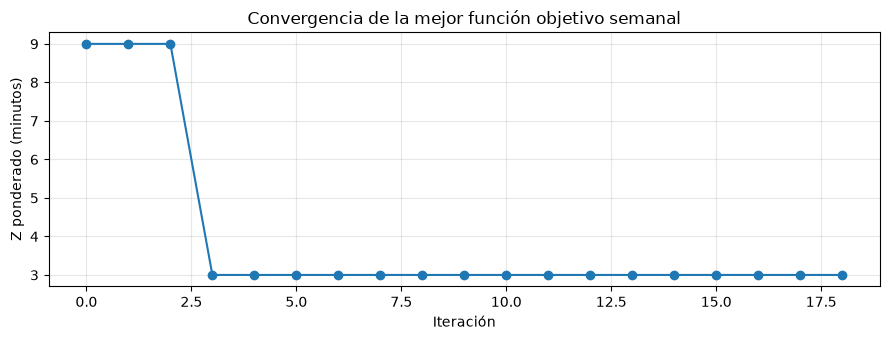

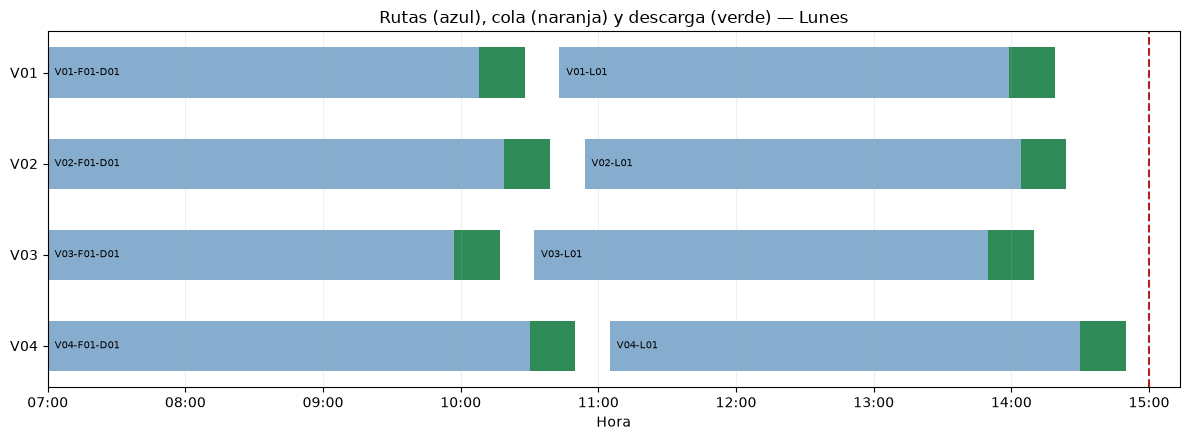

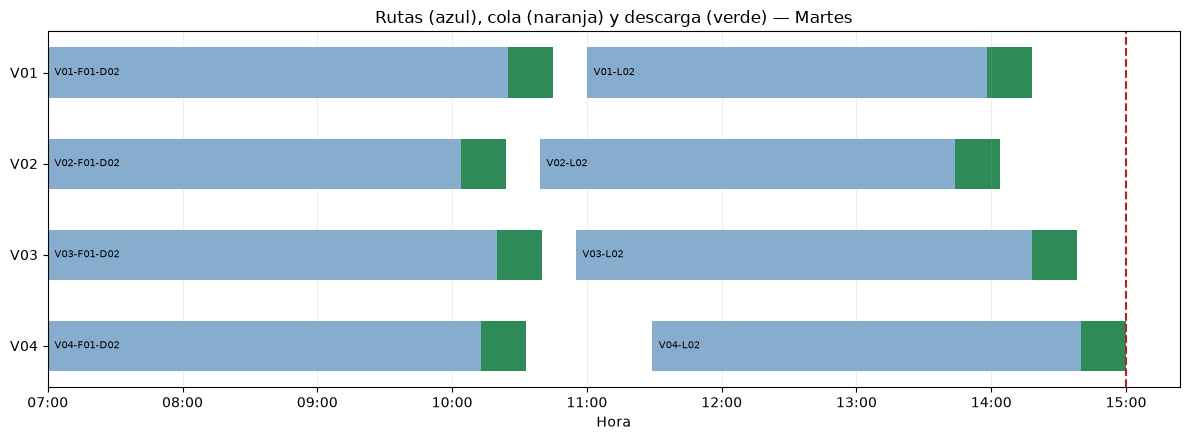

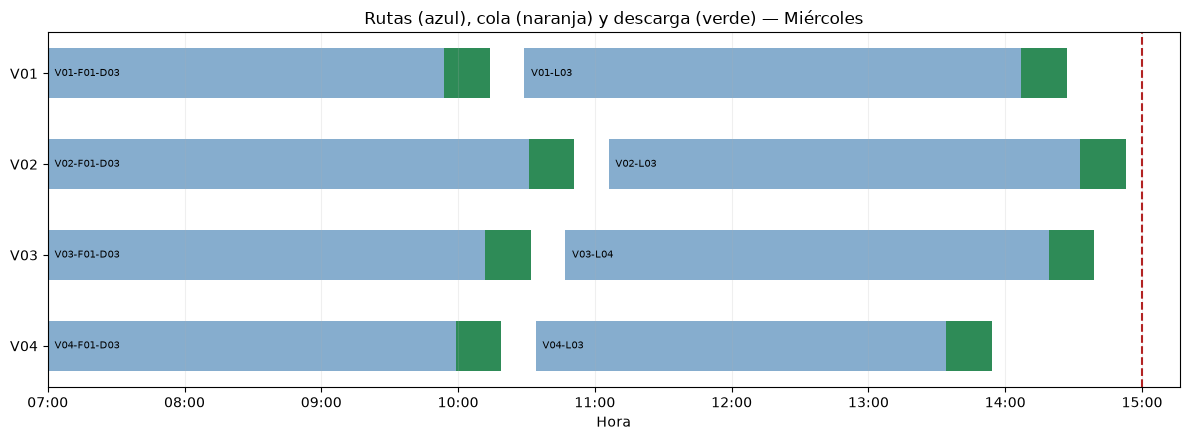

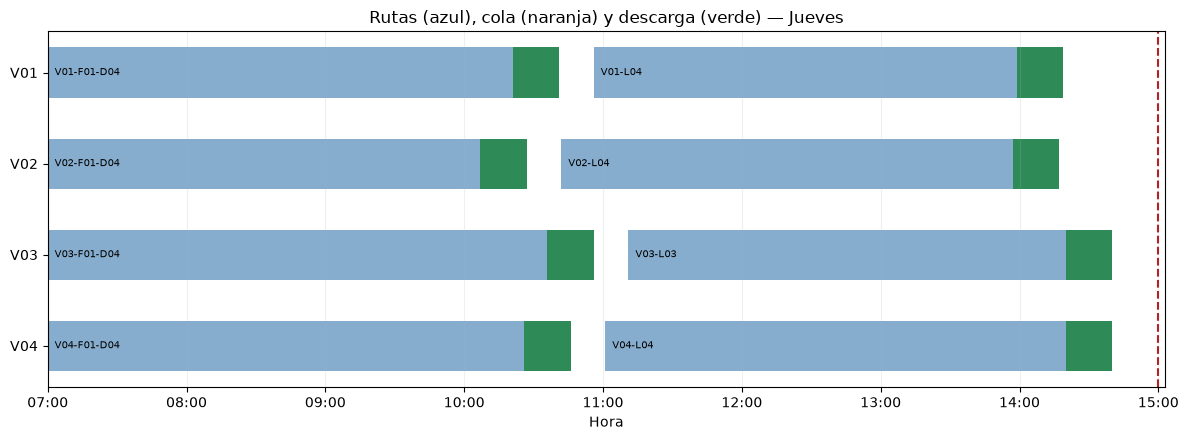

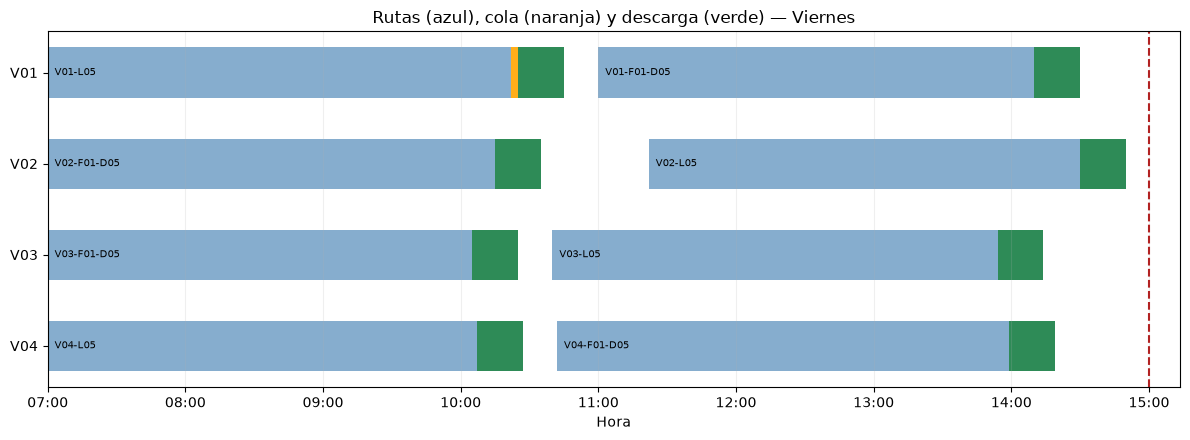

In [48]:
def hhmm(minutos):
    m = int(round(minutos))
    return f"{m//60:02d}:{m%60:02d}"

print("\nCONFIGURACIÓN SEMANAL PROPUESTA")
propuesta = mejor[["vehiculo", "ruta", "dia", "tipo", "duracion"]].copy()
propuesta["dia"] = pd.Categorical(propuesta.dia, DIAS, ordered=True)
propuesta = propuesta.sort_values(["dia", "vehiculo", "ruta"])
display(propuesta.reset_index(drop=True))

resumen = pd.DataFrame([dict(dia=d, estado=r["estado"], cola_min=r["cola"], extra_min=r["extra"], 
                             ocio_min=r["ocio"], objetivo=r["objetivo"]) for d, r in eval_mejor["diarios"].items()])
print("\nRESULTADOS DIARIOS")
display(resumen)
print("\nFUNCIONES OBJETIVO SEMANALES")
print(f"Z1 (espera en cola): {eval_mejor['cola']:.2f} minutos")
print(f"Z2 (tiempo extraordinario): {eval_mejor['extra']:.2f} minutos")
print(f"Indicador de ocio adicional: {eval_mejor['ocio']:.2f} minutos")
print(f"Z = {ALPHA_ESPERA} × Z1 + {BETA_EXTRAORDINARIO} × Z2 = {eval_mejor['objetivo']:.2f}")
print(f"Soluciones diarias diferentes evaluadas: {len(CACHE)}")

programaciones = [r["programacion"] for r in eval_mejor["diarios"].values() if r["programacion"] is not None and not r["programacion"].empty]
programacion = pd.concat(programaciones, ignore_index=True) if programaciones else pd.DataFrame()
if not programacion.empty:
    for campo in ["inicio", "llegada", "inicio_descarga", "fin_descarga"]:
        programacion[campo + "_hora"] = programacion[campo].map(hhmm)
    print("\nHORARIOS PROPUESTOS (PRIMERAS 25 OPERACIONES)")
    display(programacion[["dia", "vehiculo", "ruta", "inicio_hora", "llegada_hora", "inicio_descarga_hora", "fin_descarga_hora", "bahia", "cola", "ocio"]])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(historial.iteracion, historial.mejor, marker="o")
ax.set(title="Convergencia de la mejor función objetivo semanal", xlabel="Iteración", ylabel="Z ponderado (minutos)")
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

def diagrama_dia(dia="Lunes"):
    r = eval_mejor["diarios"][dia]
    df = r["programacion"]
    if df is None or df.empty:
        print("Sin programación factible para", dia)
        return
    vs = sorted(df.vehiculo.unique())
    fig, ax = plt.subplots(figsize=(12, 4.5))
    for _, fila in df.iterrows():
        y = vs.index(fila.vehiculo)
        # Segmento de recorrido, espera en cola y servicio de descarga.
        ax.barh(y, fila.llegada-fila.inicio, left=fila.inicio, height=.55, color="steelblue", alpha=.65)
        if fila.cola > .01:
            ax.barh(y, fila.cola, left=fila.llegada, height=.55, color="orange", alpha=.9)
        ax.barh(y, fila.fin_descarga-fila.inicio_descarga, left=fila.inicio_descarga, height=.55, color="seagreen")
        ax.text(fila.inicio+3, y, fila.ruta, va="center", fontsize=7)
    ax.axvline(HORA_FIN, color="firebrick", linestyle="--", label="Fin de jornada")
    ax.set_yticks(range(len(vs)), vs)
    ax.invert_yaxis()
    ax.set_xticks(np.arange(HORA_INICIO, max(HORA_FIN+60, df.fin_descarga.max()+30), 60))
    ax.set_xticklabels([hhmm(t) for t in ax.get_xticks()])
    ax.set(xlabel="Hora", title=f"Rutas (azul), cola (naranja) y descarga (verde) — {dia}")
    ax.grid(axis="x", alpha=.2)
    plt.tight_layout(); plt.show()

diagrama_dia("Lunes")
diagrama_dia("Martes")
diagrama_dia("Miércoles")
diagrama_dia("Jueves")
diagrama_dia("Viernes")


## 7. Verificación y exportación

La validación revisa horarios, intervalos entre rutas, bahías sin solapamiento, ventanas de asignación y consistencia del tiempo extraordinario. Los CSV se guardan en el directorio donde se ejecuta el notebook. **Nota:** no se obliga a FIFO en una cola física única; las bahías se reservan mediante una programación anticipada. Si se requiere FIFO estricto, habrá que agregar restricciones de orden de llegada o simular una disciplina de cola explícita.

In [50]:
def validar_solucion(configuracion, evaluacion, tolerancia=1e-3):
    """Valida la solución: rutas, horarios, bahías."""
    assert configuracion.ruta.is_unique, "Rutas duplicadas"
    assert configuracion.apply(lambda r: r.dia in DIAS, axis=1).all(), "Días fuera de rango"
    
    # Verificar que rutas Fijas mantienen su día asignado original
    rutas_fijas_dict = {ruta: dia for v, ruta, dia, dur in RUTAS_FIJAS}
    fijas = configuracion[configuracion.tipo.eq("Fija")]
    for idx, row in fijas.iterrows():
        ruta = row["ruta"]
        if ruta in rutas_fijas_dict:
            dia_original = rutas_fijas_dict[ruta]
            assert row["dia"] == dia_original, f"Ruta Fija {ruta} cambió de {dia_original} a {row['dia']}"
    
    # Validar programación diaria
    for dia, r in evaluacion["diarios"].items():
        df = r["programacion"]
        if df is None:
            raise AssertionError(f"Sin solución factible para {dia}")
        if df.empty:
            continue
        
        # Verificar ecuaciones temporales
        assert np.allclose(df.llegada, df.inicio + df.duracion, atol=tolerancia),             f"Inconsistencia llegada en {dia}"
        assert np.allclose(df.fin_descarga, df.inicio_descarga + TIEMPO_DESCARGA, atol=tolerancia),             f"Inconsistencia fin_descarga en {dia}"
        assert np.allclose(df.cola, df.inicio_descarga - df.llegada, atol=tolerancia),             f"Inconsistencia cola en {dia}"
        
        # Validar secuencias por vehículo
        for v, grupo in df.groupby("vehiculo"):
            orden = grupo.sort_values("inicio")
            assert abs(orden.inicio.iloc[0] - HORA_INICIO) < tolerancia,                 f"Primer inicio de {v} en {dia} no es {HORA_INICIO}"
            assert (orden.fin_descarga.max() <= HORA_FIN + r["extra_por_vehiculo"][v] + tolerancia),                 f"Horas extra de {v} en {dia} exceden límite"
            # Intervalo mínimo entre rutas
            for (_, i), (_, j) in zip(orden.iloc[:-1].iterrows(), orden.iloc[1:].iterrows()):
                assert j.inicio + tolerancia >= i.fin_descarga + TIEMPO_MINIMO_ENTRE_RUTAS,                     f"Intervalo insuficiente entre rutas de {v} en {dia}"
        
        # Validar no-solapamiento en bahías
        for bahia, grupo in df.groupby("bahia"):
            orden = grupo.sort_values("inicio_descarga")
            for (_, i), (_, j) in zip(orden.iloc[:-1].iterrows(), orden.iloc[1:].iterrows()):
                assert j.inicio_descarga + tolerancia >= i.fin_descarga,                     f"Solapamiento en bahía {bahia} el {dia}"
    
    print("[OK] Validación de asignación y programación: correcta")

if np.isfinite(eval_mejor["objetivo"]):
    validar_solucion(mejor, eval_mejor)
    propuesta.to_csv("rutas_semanales_propuestas.csv", index=False, encoding="utf-8-sig")
    resumen.to_csv("indicadores_diarios.csv", index=False, encoding="utf-8-sig")
    historial.to_csv("convergencia.csv", index=False, encoding="utf-8-sig")
    if not programacion.empty:
        programacion.to_csv("programacion_detallada.csv", index=False, encoding="utf-8-sig")
    print("CSV exportados")
else:
    print("No se encontró una programación factible; aumente TIEMPO_MILP o MAX_EXTRA.")

[OK] Validación de asignación y programación: correcta
CSV exportados
